# Battery Remaining Useful Life (RUL) Prediction

## Project Overview
This notebook demonstrates a comprehensive approach to predicting the Remaining Useful Life (RUL) of batteries using machine learning techniques. The project includes data exploration, preprocessing, feature engineering, model building, and evaluation.

## Import Required Libraries

In [2]:
# Data manipulation and analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
plt.style.use('ggplot')

# For statistical analysis
from scipy import stats

# Machine learning
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor

# Deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, GRU, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model

# Save and load models
import joblib
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Display settings
pd.set_option('display.max_columns', None)

## Load and Explore the Data

In [4]:
# Load data
print("Loading battery data...")
df = pd.read_csv('Battery_RUL.csv')

Loading battery data...


In [5]:
# Display basic information
print("\nDataset shape:", df.shape)
print("\nFirst 5 rows:")
df.head()


Dataset shape: (15064, 9)

First 5 rows:


,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL
0,1,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82,1112
1,2,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35,1111
2,3,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38,1110
3,4,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81,1109
4,6,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65,1107


In [6]:
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Cycle_Index                  0
Discharge Time (s)           0
Decrement 3.6-3.4V (s)       0
Max. Voltage Dischar. (V)    0
Min. Voltage Charg. (V)      0
Time at 4.15V (s)            0
Time constant current (s)    0
Charging time (s)            0
RUL                          0
dtype: int64


In [7]:
# Remove any missing values if present
df = df.dropna()
print(f"\nDataset shape after removing missing values: {df.shape}")


Dataset shape after removing missing values: (15064, 9)


In [8]:
# Summary statistics
print("\nSummary statistics:")
df.describe().T


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Cycle_Index,15064.0,556.155005,322.378480,1.000,271.000000,560.000000,833.0000,1134.000
Discharge Time (s),15064.0,4581.273960,33144.012077,8.690,1169.310000,1557.250000,1908.0000,958320.370
Decrement 3.6-3.4V (s),15064.0,1239.784672,15039.589269,-397645.908,319.600000,439.239471,600.0000,406703.768
Max. Voltage Dischar. (V),15064.0,3.908176,0.091003,3.043,3.846000,3.906000,3.9720,4.363
Min. Voltage Charg. (V),15064.0,3.577904,0.123695,3.022,3.488000,3.574000,3.6630,4.379
Time at 4.15V (s),15064.0,3768.336171,9129.552477,-113.584,1828.884179,2930.203500,4088.3265,245101.117
Time constant current (s),15064.0,5461.266970,25155.845202,5.980,2564.310000,3824.260000,5012.3500,880728.100
Charging time (s),15064.0,10066.496204,26415.354121,5.980,7841.922500,8320.415000,8763.2825,880728.100
RUL,15064.0,554.194172,322.434514,0.000,277.000000,551.000000,839.0000,1133.000


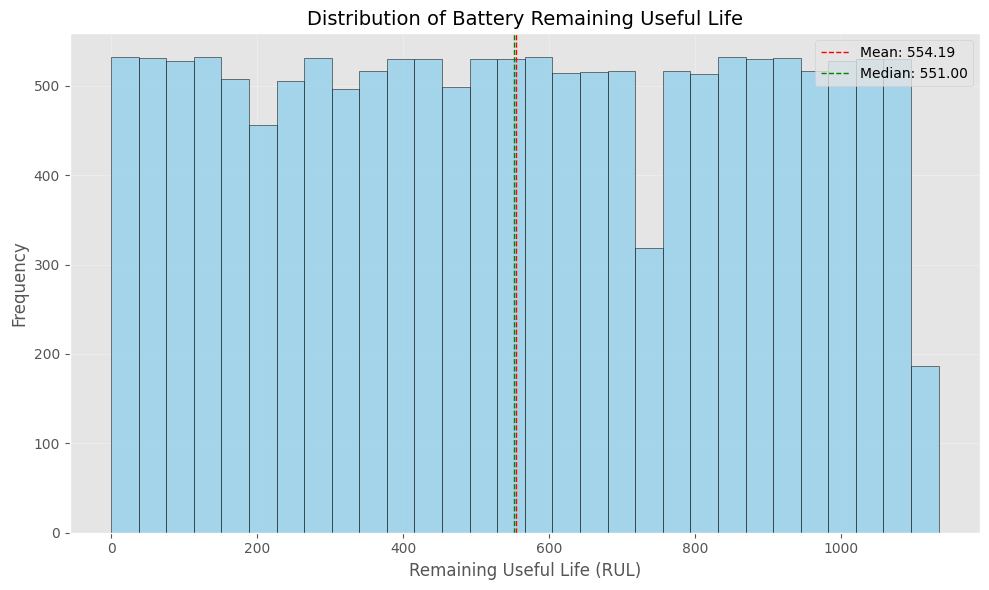

In [9]:
## Exploratory Data Analysis (EDA)

### Distribution of Target Variable

# Plot distribution of RUL
plt.figure(figsize=(10, 6))
plt.hist(df['RUL'], bins=30, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('Remaining Useful Life (RUL)')
plt.ylabel('Frequency')
plt.title('Distribution of Battery Remaining Useful Life', fontsize=14)
plt.grid(True, alpha=0.3)
plt.axvline(df['RUL'].mean(), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {df["RUL"].mean():.2f}')
plt.axvline(df['RUL'].median(), color='green', linestyle='dashed', linewidth=1, label=f'Median: {df["RUL"].median():.2f}')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
skewness = df['RUL'].skew()
print(f"Skewness of RUL: {skewness:.4f}")
if abs(skewness) > 0.5:
    print("The distribution is moderately skewed.")
elif abs(skewness) > 1:
    print("The distribution is highly skewed.")
else:
    print("The distribution is approximately symmetric.")

Skewness of RUL: 0.0062
The distribution is approximately symmetric.


### Feature Analysis

<Figure size 1200x800 with 0 Axes>

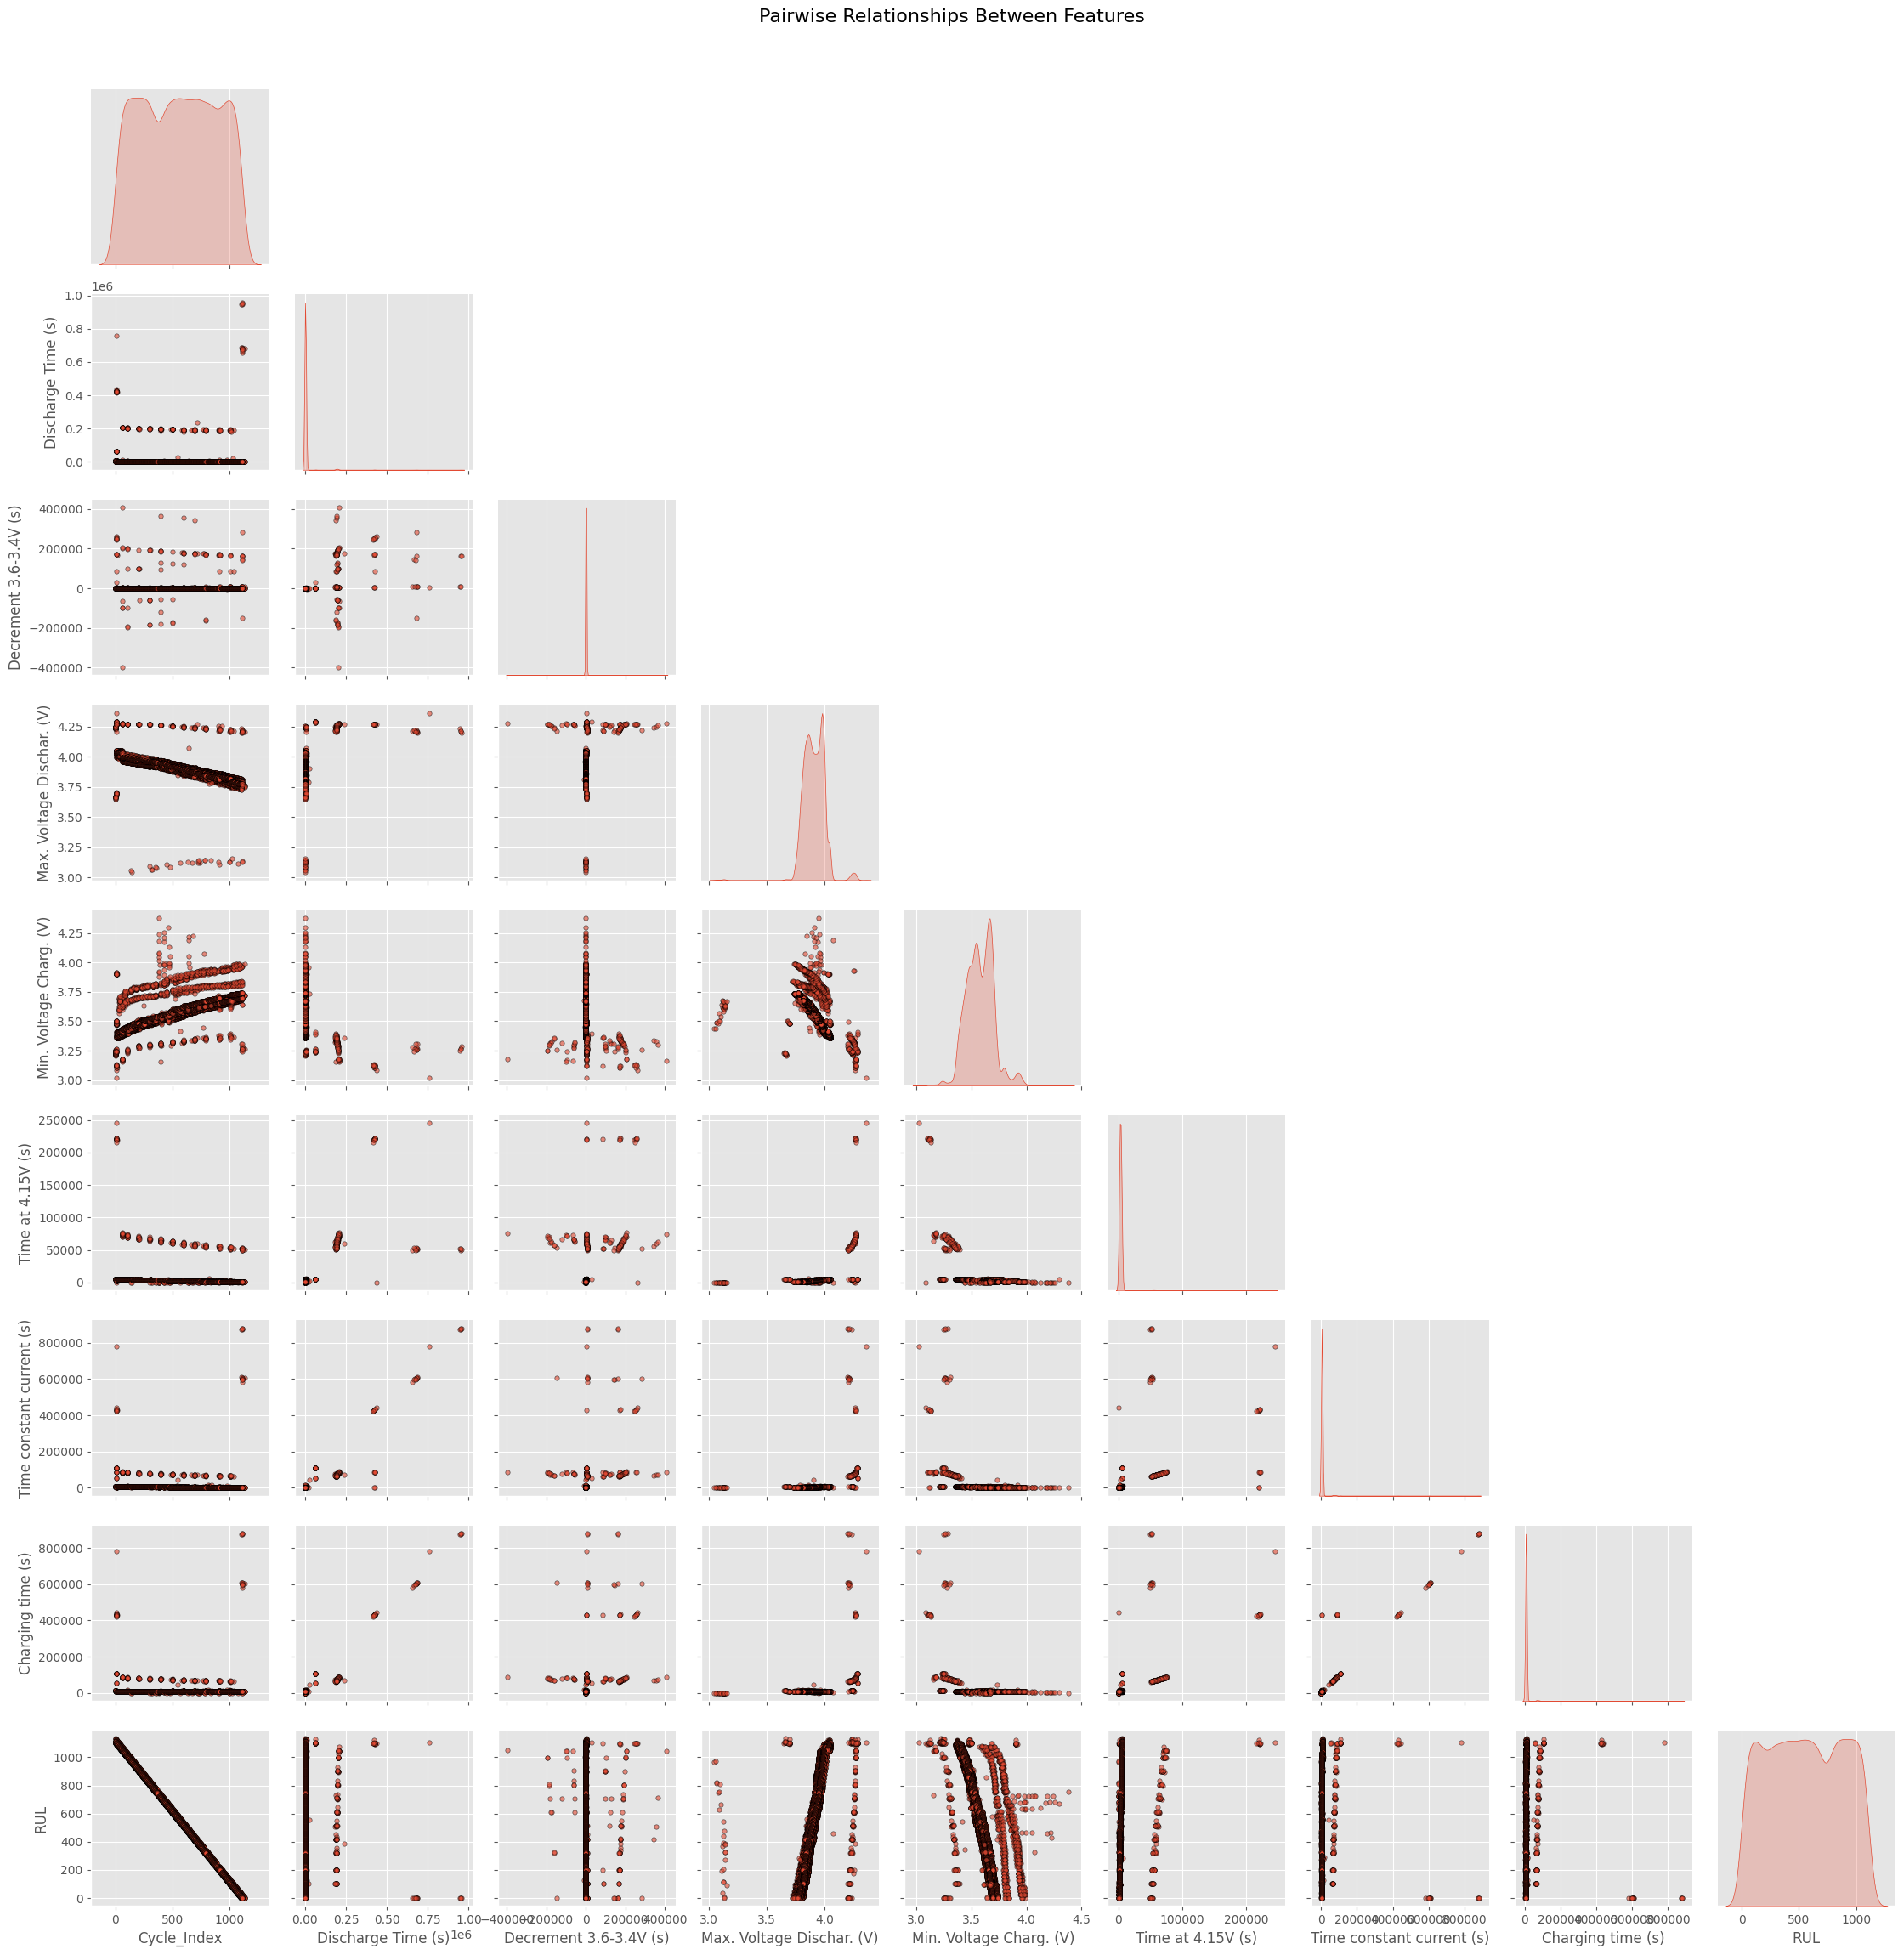

In [11]:


# Extract features for analysis
features = ['Cycle_Index', 'Discharge Time (s)', 'Decrement 3.6-3.4V (s)', 
           'Max. Voltage Dischar. (V)', 'Min. Voltage Charg. (V)', 
           'Time at 4.15V (s)', 'Time constant current (s)', 'Charging time (s)']

# Create pairplot for visual correlation analysis
plt.figure(figsize=(12, 8))
sns.pairplot(df[features + ['RUL']], corner=True, diag_kind='kde', 
             plot_kws={'alpha': 0.6, 's': 15, 'edgecolor': 'k', 'linewidth': 0.5})
plt.suptitle('Pairwise Relationships Between Features', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

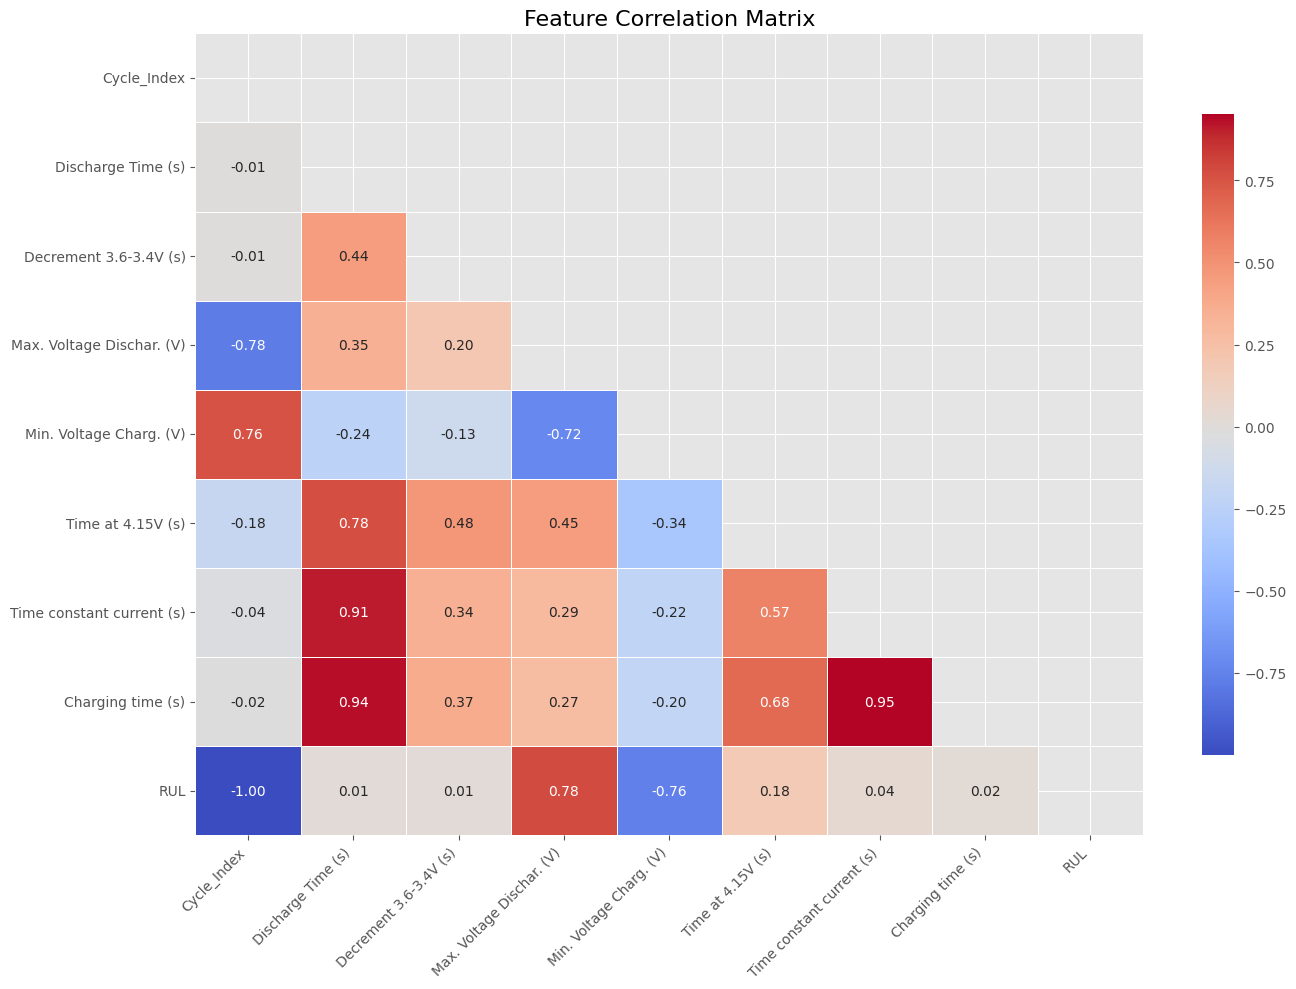

In [12]:
# Correlation analysis
plt.figure(figsize=(14, 10))
correlation = df[features + ['RUL']].corr()
mask = np.triu(correlation)
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, 
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
# Sort and print feature correlations with RUL
feature_correlations = correlation['RUL'].sort_values(ascending=False)
print("Feature correlations with RUL:")
print(feature_correlations)

Feature correlations with RUL:
RUL                          1.000000
Max. Voltage Dischar. (V)    0.782800
Time at 4.15V (s)            0.176514
Time constant current (s)    0.040675
Charging time (s)            0.018299
Decrement 3.6-3.4V (s)       0.011998
Discharge Time (s)           0.011957
Min. Voltage Charg. (V)     -0.759805
Cycle_Index                 -0.999756
Name: RUL, dtype: float64


### Feature Distributions and Outliers

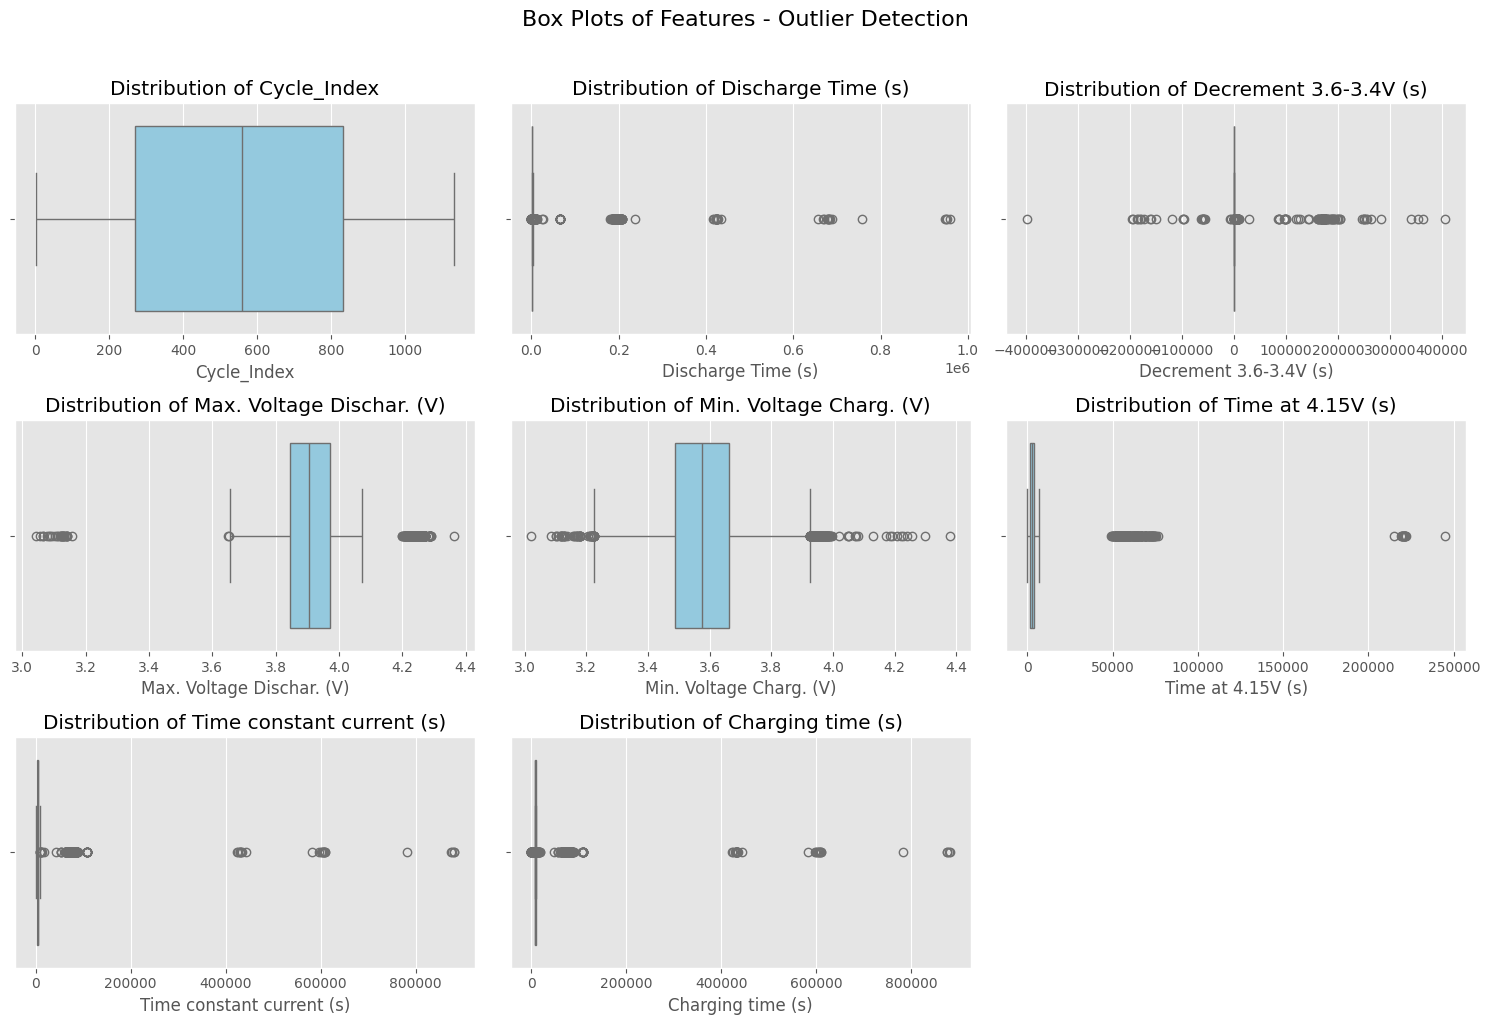

In [14]:
# Box plots to identify outliers
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features):
    plt.subplot(3, 3, i+1)
    sns.boxplot(x=df[feature], color='skyblue')
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()
plt.suptitle('Box Plots of Features - Outlier Detection', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

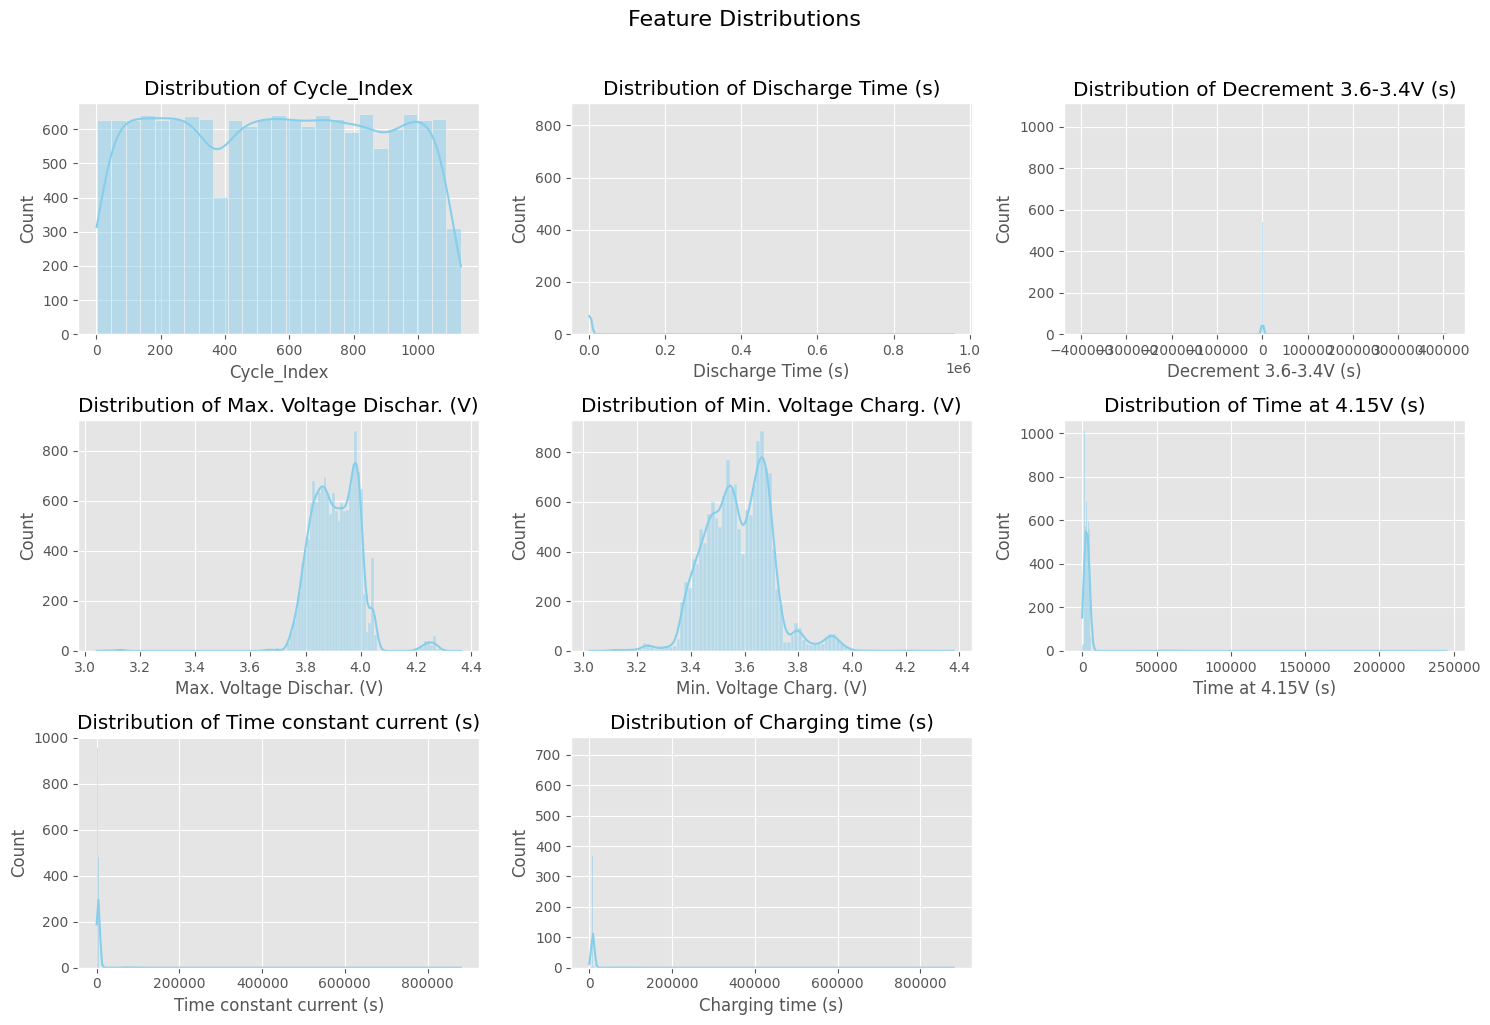

In [15]:
# Distribution of features with density plots
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features):
    plt.subplot(3, 3, i+1)
    sns.histplot(df[feature], kde=True, color='skyblue')
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()
plt.suptitle('Feature Distributions', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
skewness = df[features].skew()
print("Skewness of features:")
print(skewness)

Skewness of features:
Cycle_Index                  -0.005288
Discharge Time (s)           16.300406
Decrement 3.6-3.4V (s)        9.986258
Max. Voltage Dischar. (V)    -0.530209
Min. Voltage Charg. (V)       0.328521
Time at 4.15V (s)            16.237931
Time constant current (s)    24.723288
Charging time (s)            22.769742
dtype: float64


### Relationship Between Features and Target

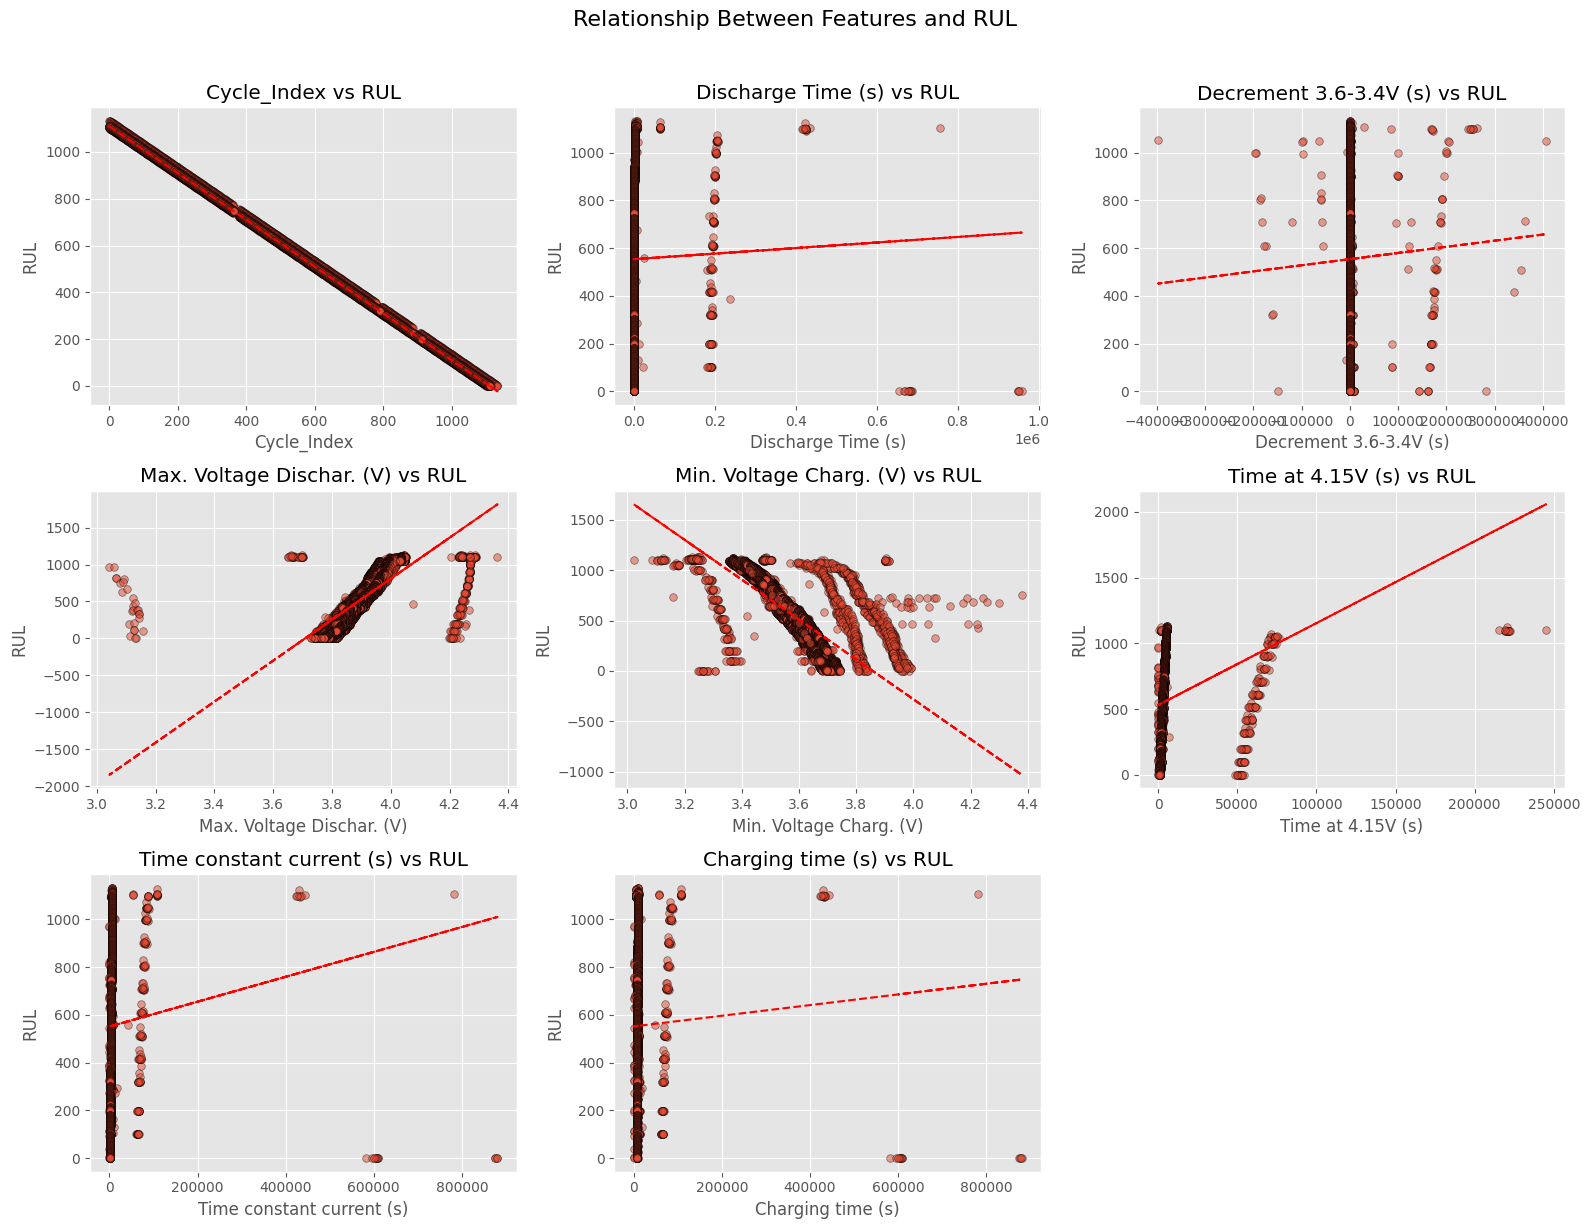

In [17]:
# Create scatter plots of each feature against RUL
plt.figure(figsize=(16, 12))
for i, feature in enumerate(features):
    plt.subplot(3, 3, i+1)
    plt.scatter(df[feature], df['RUL'], alpha=0.5, edgecolor='k', s=30)
    plt.title(f'{feature} vs RUL')
    plt.xlabel(feature)
    plt.ylabel('RUL')
    # Add regression line
    m, b = np.polyfit(df[feature], df['RUL'], 1)
    plt.plot(df[feature], m*df[feature] + b, color='red', linestyle='--')
    plt.tight_layout()
plt.suptitle('Relationship Between Features and RUL', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Feature Engineering and Selection

In [18]:
# Feature importance using SelectKBest (f_regression)
X = df[features]
y = df['RUL']

# Perform feature selection
selector = SelectKBest(f_regression, k='all')
selector.fit(X, y)

# Get scores and p-values
scores = selector.scores_
pvalues = selector.pvalues_

# Display feature importance
feature_scores = pd.DataFrame({
    'Feature': features,
    'Score': scores,
    'P-value': pvalues
})

feature_scores = feature_scores.sort_values('Score', ascending=False)
print("Feature importance based on F-regression:")
print(feature_scores)

Feature importance based on F-regression:
                     Feature         Score        P-value
0                Cycle_Index  3.086275e+07   0.000000e+00
3  Max. Voltage Dischar. (V)  2.383533e+04   0.000000e+00
4    Min. Voltage Charg. (V)  2.057112e+04   0.000000e+00
5          Time at 4.15V (s)  4.843826e+02  1.093584e-105
6  Time constant current (s)  2.496083e+01   5.916268e-07
7          Charging time (s)  5.045108e+00   2.471000e-02
2     Decrement 3.6-3.4V (s)  2.168676e+00   1.408684e-01
1         Discharge Time (s)  2.153617e+00   1.422553e-01


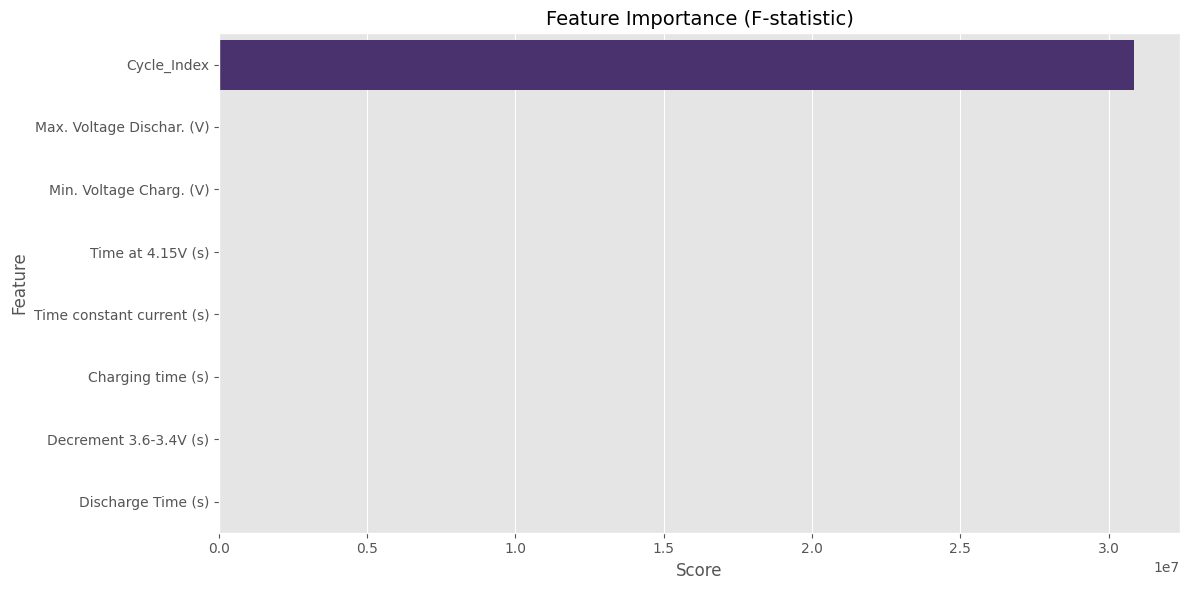

In [19]:
# Visualize feature importance
plt.figure(figsize=(12, 6))
sns.barplot(x='Score', y='Feature', data=feature_scores, palette='viridis')
plt.title('Feature Importance (F-statistic)', fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# Principal Component Analysis (PCA)
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X)

In [21]:
# Apply PCA
pca = PCA()
pca_result = pca.fit_transform(X_scaled_pca)

In [22]:
# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

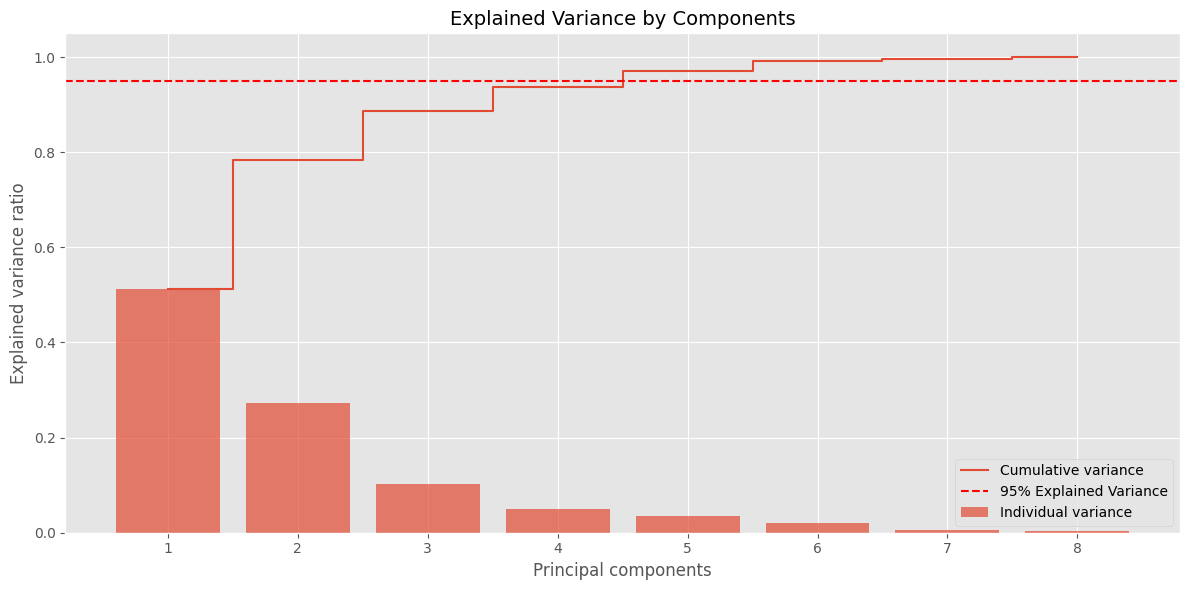

In [23]:
# Plot explained variance
plt.figure(figsize=(12, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, 
        alpha=0.7, align='center', label='Individual variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, 
         where='mid', label='Cumulative variance')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Explained Variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal components')
plt.title('Explained Variance by Components', fontsize=14)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [24]:
# Print the number of components needed for 95% variance
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Number of components needed for 95% variance: {n_components_95}")

Number of components needed for 95% variance: 5


In [25]:
## Data Preprocessing and Splitting

# Split features and target
X = df[features]
y = df['RUL']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 12051 samples
Test set size: 3013 samples


In [26]:
# Try different scaling methods to see which works best
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

In [27]:
# Create a dict to store scaled data
scaled_data = {}

for name, scaler in scalers.items():
    # Fit on training data
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Store the scaled data
    scaled_data[name] = (X_train_scaled, X_test_scaled)
    
    # Show first few rows of scaled train data
    print(f"\n{name} - First 3 rows of scaled training data:")
    print(pd.DataFrame(X_train_scaled[:3], columns=features))

# Decide on the best scaler - Standard Scaler is commonly used for neural networks
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nSelected StandardScaler for the final model.")


StandardScaler - First 3 rows of scaled training data:
   Cycle_Index  Discharge Time (s)  Decrement 3.6-3.4V (s)  \
0    -1.270053           -0.075516               -0.045164   
1     0.299052           -0.097013               -0.062694   
2     0.745595           -0.101238               -0.063616   

   Max. Voltage Dischar. (V)  Min. Voltage Charg. (V)  Time at 4.15V (s)  \
0                   0.428716                -0.896800           0.097301   
1                  -0.731758                 0.335331          -0.150033   
2                  -0.419323                 0.441408          -0.179283   

   Time constant current (s)  Charging time (s)  
0                   0.012176          -0.029175  
1                  -0.089464          -0.072726  
2                  -0.106130          -0.089909  

MinMaxScaler - First 3 rows of scaled training data:
   Cycle_Index  Discharge Time (s)  Decrement 3.6-3.4V (s)  \
0     0.127096            0.002151                0.523150   
1     0.5736

## Baseline Model - Random Forest

Training baseline Random Forest model...

Random Forest Baseline Model Metrics:
MAE: 2.1205
MSE: 14.4535
RMSE: 3.8018
R²: 0.9999
MAPE: 3766701314627.8481


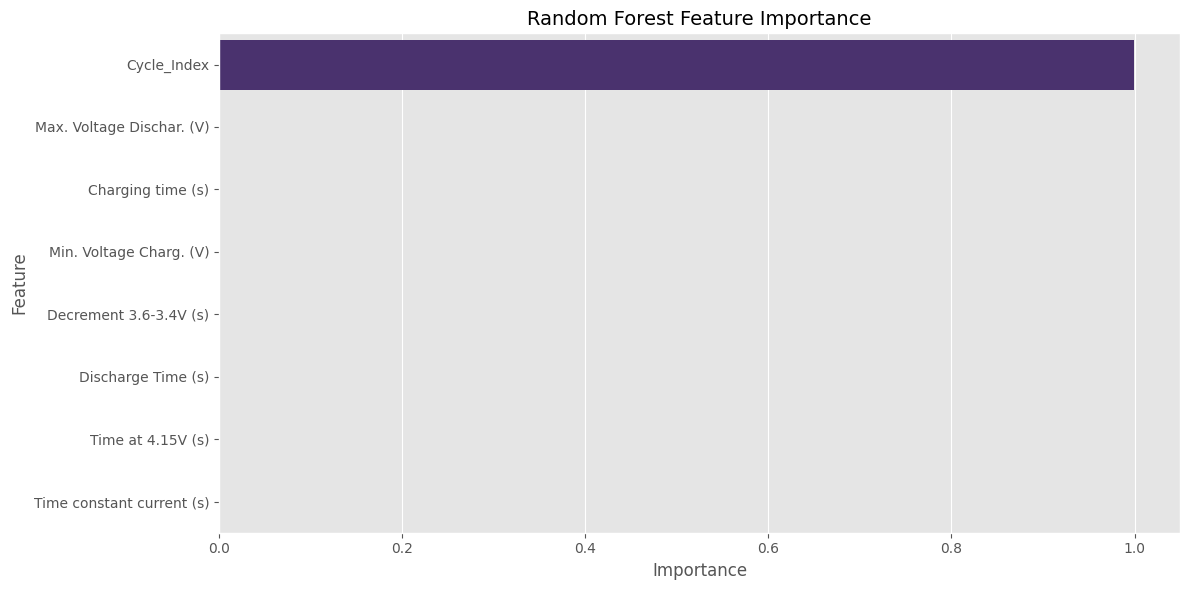

In [29]:
# Create a simple Random Forest model as baseline
print("Training baseline Random Forest model...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Evaluate on test set
y_pred_rf = rf_model.predict(X_test_scaled)

# Calculate metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf)

print(f"\nRandom Forest Baseline Model Metrics:")
print(f"MAE: {mae_rf:.4f}")
print(f"MSE: {mse_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²: {r2_rf:.4f}")
print(f"MAPE: {mape_rf:.4f}")

# Plot feature importance
plt.figure(figsize=(12, 6))
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Random Forest Feature Importance', fontsize=14)
plt.tight_layout()
plt.show()

## CNN Model Development

### Reshape Data for CNN

In [30]:
# Reshape data for CNN (samples, timesteps, features)
X_train_reshaped = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_reshaped = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

print(f"Training data shape after reshaping: {X_train_reshaped.shape}")
print(f"Test data shape after reshaping: {X_test_reshaped.shape}")

Training data shape after reshaping: (12051, 8, 1)
Test data shape after reshaping: (3013, 8, 1)


### Build CNN Model

In [31]:
# Build CNN model
print("Building CNN model...")
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train_reshaped.shape[1], 1)))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))
model.add(Conv1D(filters=32, kernel_size=2, activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(100, activation='relu', kernel_regularizer='l2'))
model.add(Dense(50, activation='relu'))
model.add(Dense(1))

# Print model summary
model.summary()

# Compile model
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

Building CNN model...
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 6, 64)             256       
                                                                 
 max_pooling1d (MaxPooling1D  (None, 3, 64)            0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 3, 64)             0         
                                                                 
 conv1d_1 (Conv1D)           (None, 2, 32)             4128      
                                                                 
 max_pooling1d_1 (MaxPooling  (None, 1, 32)            0         
 1D)                                                             
                                                                 
 dropout_1 (Dropout)         (None

### Train and Monitor the Model

In [32]:
# Set up callbacks for better training
checkpoint_path = "model_checkpoints/best_model.h5"
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_loss', verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001, verbose=1)

# Train model
print("\nTraining CNN model...")
history = model.fit(
    X_train_reshaped, y_train, 
    validation_split=0.2, 
    epochs=100, 
    batch_size=32, 
    callbacks=[early_stop, checkpoint, reduce_lr],
    verbose=1
)


Training CNN model...
Epoch 1/100
291/302 [===========================>..] - ETA: 0s - loss: 177066.4531 - mae: 341.3191
Epoch 00001: val_loss improved from inf to 52393.78906, saving model to model_checkpoints\best_model.h5
302/302 [==============================] - 3s 6ms/step - loss: 172900.7188 - mae: 336.4203 - val_loss: 52393.7891 - val_mae: 192.3990 - lr: 0.0010
Epoch 2/100
299/302 [============================>.] - ETA: 0s - loss: 31291.2500 - mae: 136.6204
Epoch 00002: val_loss improved from 52393.78906 to 9785.78125, saving model to model_checkpoints\best_model.h5
302/302 [==============================] - 1s 5ms/step - loss: 31217.2090 - mae: 136.3056 - val_loss: 9785.7812 - val_mae: 66.1065 - lr: 0.0010
Epoch 3/100
289/302 [===========================>..] - ETA: 0s - loss: 18354.9805 - mae: 100.7548
Epoch 00003: val_loss improved from 9785.78125 to 8217.41992, saving model to model_checkpoints\best_model.h5
302/302 [==============================] - 1s 4ms/step - loss: 181


### Evaluate Model Performance

In [33]:

# Evaluate model
y_pred = model.predict(X_test_reshaped)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

# Store metrics
metrics = {
    'MAE': mae,
    'MSE': mse,
    'RMSE': rmse,
    'R2': r2,
    'MAPE': mape
}

print(f"\nCNN Model Metrics:")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")
print(f"MAPE: {mape:.4f}")


CNN Model Metrics:
MAE: 33.4514
MSE: 2221.2328
RMSE: 47.1300
R²: 0.9786
MAPE: 1258278570615167.7500


In [34]:
# Compare with baseline model
print("\nPerformance Comparison:")
print(f"{'Metric':<10} {'Random Forest':<15} {'CNN':<15}")
print(f"{'-'*40}")
print(f"{'MAE':<10} {mae_rf:<15.4f} {mae:<15.4f}")
print(f"{'MSE':<10} {mse_rf:<15.4f} {mse:<15.4f}")
print(f"{'RMSE':<10} {rmse_rf:<15.4f} {rmse:<15.4f}")
print(f"{'R²':<10} {r2_rf:<15.4f} {r2:<15.4f}")
print(f"{'MAPE':<10} {mape_rf:<15.4f} {mape:<15.4f}")


Performance Comparison:
Metric     Random Forest   CNN            
----------------------------------------
MAE        2.1205          33.4514        
MSE        14.4535         2221.2328      
RMSE       3.8018          47.1300        
R²         0.9999          0.9786         
MAPE       3766701314627.8481 1258278570615167.7500


### Visualize Training History

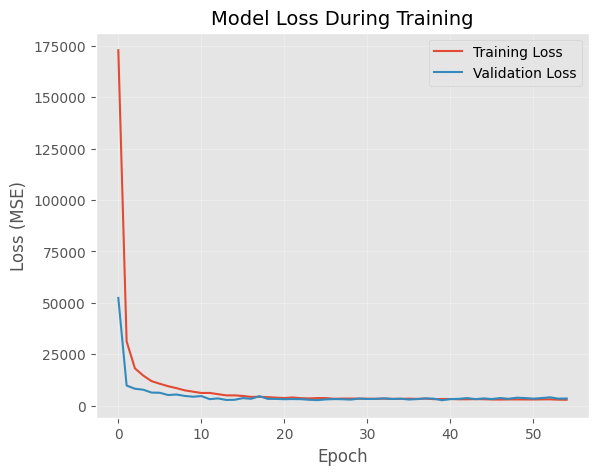

In [35]:


# Plot training history
plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss During Training', fontsize=14)
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

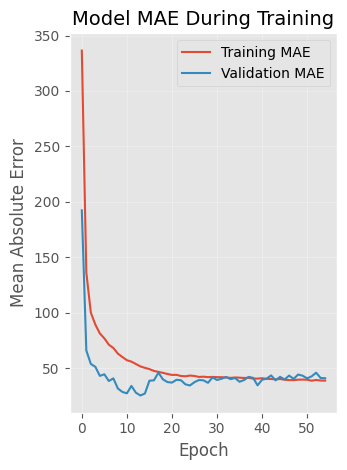

In [36]:
# MAE plot
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE During Training', fontsize=14)
plt.ylabel('Mean Absolute Error')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Extract final epoch metrics
final_epoch = len(history.history['loss'])
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
final_train_mae = history.history['mae'][-1]
final_val_mae = history.history['val_mae'][-1]

print(f"\nTraining completed in {final_epoch} epochs")
print(f"Final training loss: {final_train_loss:.4f}")
print(f"Final validation loss: {final_val_loss:.4f}")
print(f"Final training MAE: {final_train_mae:.4f}")
print(f"Final validation MAE: {final_val_mae:.4f}")


Training completed in 55 epochs
Final training loss: 2860.8362
Final validation loss: 3471.0215
Final training MAE: 38.8895
Final validation MAE: 41.0445


### Visualize Predictions

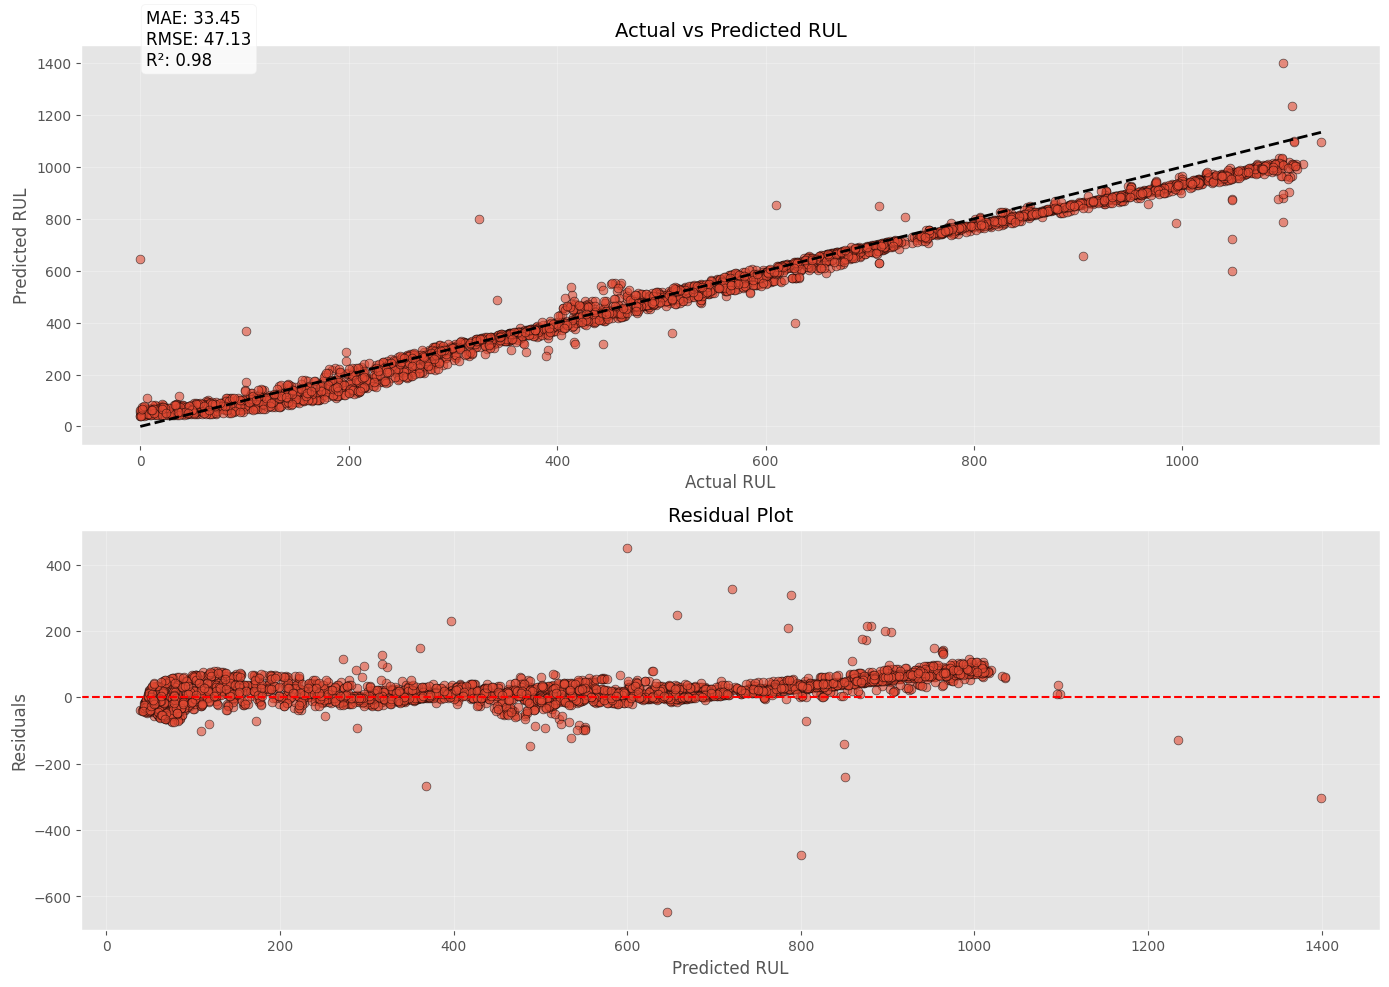

In [38]:

# Plot predictions vs actual
plt.figure(figsize=(14, 10))

# Scatter plot
plt.subplot(2, 1, 1)
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor='k', s=40)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL', fontsize=14)
plt.grid(True, alpha=0.3)

# Add text for metrics
plt.text(0.05, 0.95, f'MAE: {mae:.2f}\nRMSE: {rmse:.2f}\nR²: {r2:.2f}', 
         transform=plt.gca().transAxes, fontsize=12, 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Residual plot
plt.subplot(2, 1, 2)
residuals = y_test - y_pred.flatten()
plt.scatter(y_pred.flatten(), residuals, alpha=0.6, edgecolor='k', s=40)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted RUL')
plt.ylabel('Residuals')
plt.title('Residual Plot', fontsize=14)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

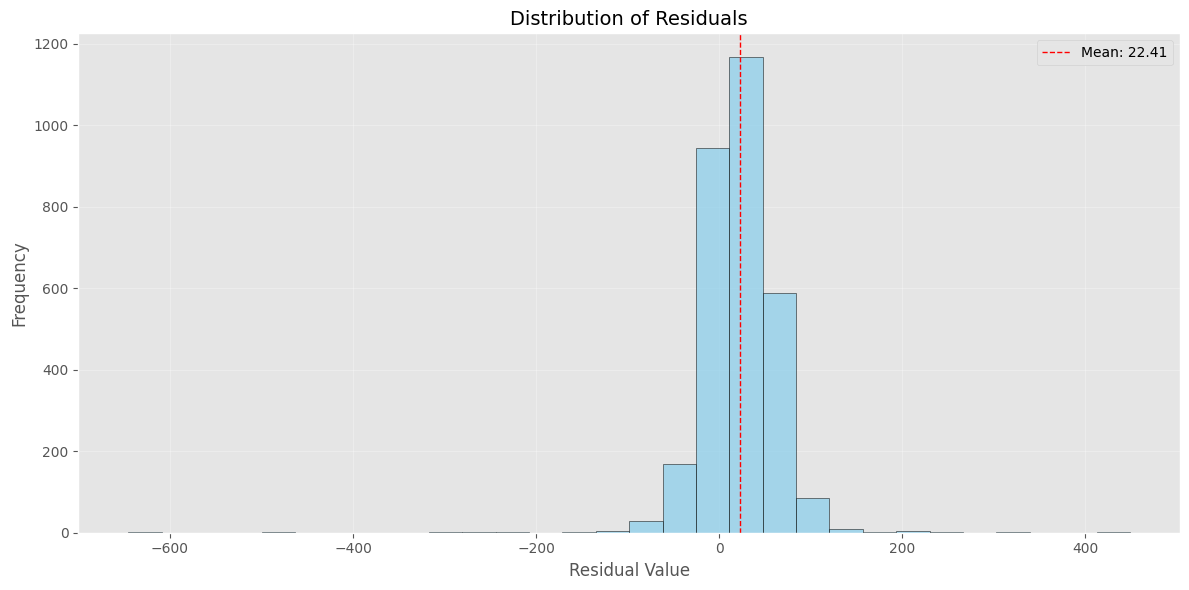

In [40]:
# Check distribution of residuals
plt.figure(figsize=(12, 6))
plt.hist(residuals, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(residuals.mean(), color='red', linestyle='dashed', linewidth=1, 
            label=f'Mean: {residuals.mean():.2f}')
plt.xlabel('Residual Value')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



In [41]:
print(f"Mean of residuals: {residuals.mean():.4f}")
print(f"Standard deviation of residuals: {residuals.std():.4f}")

Mean of residuals: 22.4071
Standard deviation of residuals: 41.4696


In [42]:



## Save Model and Artifacts


# Save model
model.save('battery_rul_cnn.h5')
joblib.dump(scaler, 'scaler.save')

# Save metrics
with open('model_metrics.txt', 'w') as f:
    for key, value in metrics.items():
        f.write(f"{key}: {value}\n")

# Save the Random Forest model as well
joblib.dump(rf_model, 'battery_rul_rf.joblib')

print("Models and artifacts saved successfully.")

Models and artifacts saved successfully.


In [43]:
def predict_rul(input_data, model_type='cnn'):
    """
    Predict RUL from input data
    
    Parameters:
    -----------
    input_data : list or numpy array
        Features in the same order as training data:
        [Cycle_Index, Discharge Time, Decrement 3.6-3.4V, Max. Voltage Dischar., 
         Min. Voltage Charg., Time at 4.15V, Time constant current, Charging time]
    model_type : str, optional
        'cnn' or 'rf', default is 'cnn'
        
    Returns:
    --------
    float
        Predicted RUL
    """
    # Ensure input is numpy array
    if not isinstance(input_data, np.ndarray):
        input_data = np.array(input_data).reshape(1, -1)
    
    # Load scaler
    loaded_scaler = joblib.load('scaler.save')
    
    # Preprocess input
    scaled_input = loaded_scaler.transform(input_data)
    
    # Make prediction based on model type
    if model_type.lower() == 'cnn':
        # Load CNN model
        loaded_model = tf.keras.models.load_model('battery_rul_cnn.h5')
        # Reshape for CNN
        reshaped_input = scaled_input.reshape((scaled_input.shape[0], scaled_input.shape[1], 1))
        # Predict
        prediction = loaded_model.predict(reshaped_input)
        return prediction[0][0]
    elif model_type.lower() == 'rf':
        # Load RF model
        loaded_model = joblib.load('battery_rul_rf.joblib')
        # Predict
        prediction = loaded_model.predict(scaled_input)
        return prediction[0]
    else:
        raise ValueError("Model type must be 'cnn' or 'rf'")

# TESING

In [44]:

# Example usage
print("Testing prediction function with sample data...")

# Sample data: [Cycle_Index, Discharge Time, Decrement 3.6-3.4V, Max. Voltage Dischar., 
#               Min. Voltage Charg., Time at 4.15V, Time constant current, Charging time]
sample_data = [100, 120, 45, 3.9, 3.2, 200, 350, 500]

# Predict using both models
cnn_prediction = predict_rul(sample_data, model_type='cnn')
rf_prediction = predict_rul(sample_data, model_type='rf')

print(f"Sample input data: {sample_data}")
print(f"CNN model prediction: {cnn_prediction:.2f} cycles of RUL")
print(f"Random Forest prediction: {rf_prediction:.2f} cycles of RUL")





Testing prediction function with sample data...
Sample input data: [100, 120, 45, 3.9, 3.2, 200, 350, 500]
CNN model prediction: 1017.80 cycles of RUL
Random Forest prediction: 1022.91 cycles of RUL


In [45]:
# Summary of findings
print("Project Summary and Conclusions:")
print("-" * 50)
print("1. Data Exploration:")
print("   - Analyzed battery health data with focus on Remaining Useful Life (RUL)")
print("   - Identified key features and their relationships with RUL")
print("   - Discovered correlations and distributions that inform model development")
print("\n2. Model Performance:")
print(f"   - CNN Model achieved R² of {r2:.4f} and RMSE of {rmse:.4f}")
print(f"   - Random Forest baseline achieved R² of {r2_rf:.4f} and RMSE of {rmse_rf:.4f}")
print(f"   - CNN {'outperformed' if r2 > r2_rf else 'underperformed compared to'} Random Forest")
print("\n3. Key Features:")
top_features = feature_importance['Feature'].iloc[:3].tolist()
print(f"   - Most important features from Random Forest: {', '.join(top_features)}")
print("\n4. Next Steps:")
print("   - Consider hyperparameter tuning for further optimization")
print("   - Explore other architectures (LSTM, GRU) for time series aspects")
print("   - Implement cross-validation for more robust evaluation")
print("   - Develop a feature selection pipeline to reduce dimensionality")
print("   - Create a web interface or API for deployment")

Project Summary and Conclusions:
--------------------------------------------------
1. Data Exploration:
   - Analyzed battery health data with focus on Remaining Useful Life (RUL)
   - Identified key features and their relationships with RUL
   - Discovered correlations and distributions that inform model development

2. Model Performance:
   - CNN Model achieved R² of 0.9786 and RMSE of 47.1300
   - Random Forest baseline achieved R² of 0.9999 and RMSE of 3.8018
   - CNN underperformed compared to Random Forest

3. Key Features:
   - Most important features from Random Forest: Cycle_Index, Max. Voltage Dischar. (V), Charging time (s)

4. Next Steps:
   - Consider hyperparameter tuning for further optimization
   - Explore other architectures (LSTM, GRU) for time series aspects
   - Implement cross-validation for more robust evaluation
   - Develop a feature selection pipeline to reduce dimensionality
   - Create a web interface or API for deployment
